# Group Homework 3 · The GoMart report makeover
**Data Visualization · UEH · Session 3** · team notebook

| | |
|---|---|
| **Team** | *team name* · **team number** (from the LMS list): __ |
| **Status** | Formative: written feedback with the rubric in the brief. Task 0 is the first version of Module M3 of your project |
| **Submit** | File ▸ Download ▸ .ipynb as `GH3_TeamName.ipynb` + the evidence folder of Task 4, within 7 days on the LMS |

Read the brief *Group Homework 3* first. All GoMart data is simulated.

## Task 5 · One-page summary for the operations director (write this last)
**Big Idea:** *one complete sentence.*

*At most 100 words. The one-page figure is made in the last code cell of the notebook (it needs everything above);
after "Restart and run all", paste its image here.*

## Task 0 · Project: house style v0 and makeover plan (Module M3)
**Allocated project:** P__ · *title*

1. Put your `house_style.py` v0 in the cell below (palette in fixed order, sequential map, diverging map, fonts, number format).
2. Show the evidence: a swatch of your palette in colour, in greyscale and with simulated deuteranopia.
3. Makeover plan for one published chart from your domain: link, screenshot, critique table, photo of your hand sketch.

In [9]:
# Task 0 · house_style.py v0 for your project (paste the file content here, then run it)
# PROJECT_PALETTE = [...]       # fixed order, one colour per category of your project
# SEQ_CMAP = "..."; DIV_CMAP = "..."
# def use_house_style(): ...

In [10]:
# Task 0 · evidence: palette swatch in colour, greyscale, deuteranopia
# (use fig_to_rgb, to_grey and simulate_cvd from the Setup section below)

| # | What I see | Principle broken (name it) | Effect on the reader | My fix |
|---|---|---|---|---|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |
| 4 | | | | |

## Setup
Upload `gomart_orders_2025_clean.csv`, `gomart_districts.csv` and `gomart_targets_2025.csv`.
Run `gomart_bad_report.py` once (or open `gomart_bad_report.pdf`) to see the six charts you will audit.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import TwoSlopeNorm, to_rgb

GREY, LIGHT, DARK, BLUE, ORANGE = "#a3a29c", "#d9d8d3", "#52514e", "#2a78d6", "#eb6834"
ZONE_COLOR = {"Central": "#a9c9ef", "Inner": "#5b9be3", "Outer": "#1f4f8f"}   # ordered: light -> dark

In [12]:
orders = pd.read_csv("gomart_orders_2025_clean.csv", parse_dates=["order_time"])
districts = pd.read_csv("gomart_districts.csv")
targets = pd.read_csv("gomart_targets_2025.csv")
orders = orders.merge(districts, on="district", how="left", validate="many_to_one")
orders["month"] = orders["order_time"].dt.strftime("%Y-%m")
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
orders["weekday"] = pd.Categorical(orders["order_time"].dt.strftime("%a"), categories=days, ordered=True)
orders["hour"] = orders["order_time"].dt.hour
tiers = ["none", "Silver", "Gold", "Platinum"]
orders["member_tier"] = pd.Categorical(orders["member_tier"], categories=tiers, ordered=True)
delivered = orders[orders["status"] == "delivered"]
print(orders.shape, "| orders without zone:", orders["zone"].isna().sum())

(5913, 16) | orders without zone: 0


Helper functions from Tutorial 3 (given):

In [13]:
def fig_to_rgb(fig):
    fig.canvas.draw()
    return np.asarray(fig.canvas.buffer_rgba())[..., :3] / 255

def to_grey(rgb):
    return np.asarray(rgb)[..., :3] @ np.array([0.299, 0.587, 0.114])

DEUTAN = np.array([[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413],
                   [-0.011820, 0.042940, 0.968881]])

def simulate_cvd(rgb, M=DEUTAN):
    lin = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    sim = np.clip(lin @ M.T, 0, 1)
    return np.where(sim <= 0.0031308, 12.92 * sim, 1.055 * sim ** (1 / 2.4) - 0.055)

## Task 1 · Audit the report
For each of the six charts: the task the chart should support (action + target), then at least four problems.

| Chart | Task it should support | Problem | Principle (name it) | Effect on the reader |
|---|---|---|---|---|
| 1 Orders by district | | | | |
| 1 | | | | |
| 2 Payments | | | | |
| ... | | | | |
| 4 Peak times | Identify peak ordering hours and days across the week to allocate staff and riders | Use rainbow colormap `cmap="jet"` for order volume | Expressiveness & Perceptually uniform map | Luminance $L^*$ changes unpredictably, creating artificial boundaries; in greyscale or for colour-blind viewers, the data peak (Tuesday 19:00) turns dark, distorting information |
| 4 | | Days of the week ordered alphabetically A-Z (*Friday, Monday...*) | Expressiveness & Gestalt Continuity | Breaks the natural chronological time sequence, forcing readers to search item-by-item, increasing cognitive load |
| 4 | | Generic topic title: `"Orders heatmap"` | Direct attention & Action title | Fails to convey the main message; managers must spend time manually scanning to find peak hours |
| 4 | | Colorbar lacks measurement unit and is not anchored at `vmin=0` | Clutter & Encoding Integrity | Readers cannot tell whether measurement unit is order count or revenue; unanchored zero distorts density comparison |

## Task 2 · Redesign
### Chart 1 · Orders by district
*Task:* ...  *Why this chart:* ...

In [14]:
# TODO: write your code here

In [15]:
# TODO: write your code here

### Chart 2 · Payments
*Task:* ...  *Why this chart:* ...

In [16]:
# TODO: write your code here

### Chart 3 · Delivery time
*Task:* ...  *Why this chart:* ...

In [17]:
# TODO: write your code here

In [18]:
# TODO: write your code here

### Chart 4 · Peak times
*Task:* Identify peak ordering hours and days across the week to allocate staff and delivery riders efficiently.  </br>
*Why this chart:* A 2D heatmap with a chronological calendar layout (Mon–Sun) and a single-hue sequential colormap (`Blues`) encodes order volume into monotonic lightness ($L^*$), making peak operational rush hours instantly identifiable without clutter or rainbow distortion.

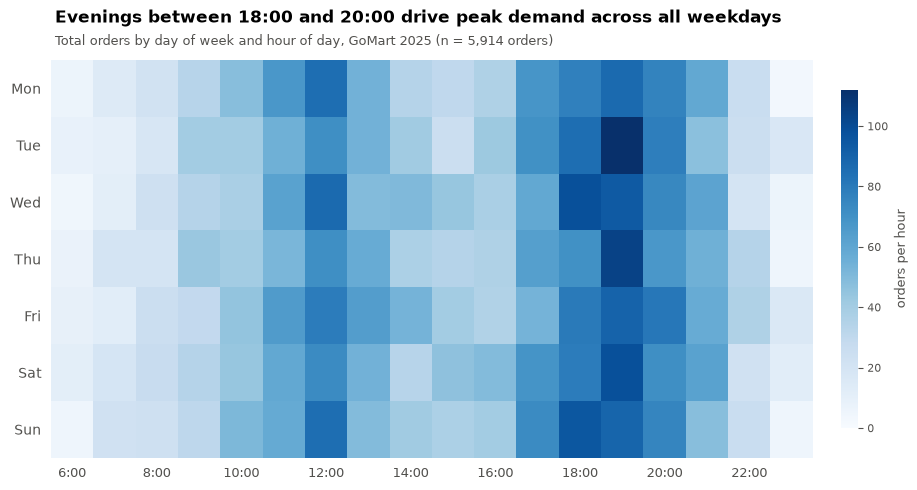

In [ ]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
orders["weekday"] = pd.Categorical(orders["order_time"].dt.strftime("%a"), categories=days, ordered=True)
orders["hour"] = orders["order_time"].dt.hour

t = orders.pivot_table(index="weekday", columns="hour", values="order_id", aggfunc="count", observed=False).fillna(0)

fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(t.values, cmap="Blues", aspect="auto", vmin=0)

ax.set_yticks(range(len(t.index)))
ax.set_yticklabels(t.index, fontsize=10, color=DARK)

tick_indices = list(range(0, len(t.columns), 2))
ax.set_xticks(tick_indices)
ax.set_xticklabels([f"{t.columns[i]}:00" for i in tick_indices], fontsize=9, color=DARK)

cbar = fig.colorbar(im, ax=ax, pad=0.03, shrink=0.85)
cbar.set_label("orders per hour", fontsize=9, color=DARK)
cbar.ax.tick_params(labelsize=8, colors=DARK)
cbar.outline.set_visible(False)

for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(left=False, bottom=False)

fig.text(0.06, 1.05, "Evenings between 18:00 and 20:00 drive peak demand across all weekdays",
         fontsize=12, weight="bold", color="black", ha="left")
fig.text(0.06, 1.00, "Total orders by day of week and hour of day, GoMart 2025 (n = 5,914 orders)",
         fontsize=9.5, color=DARK, ha="left")

plt.tight_layout()
plt.show()

In [32]:
# Check numbers for Chart 4 Action Title
total_orders = orders.shape[0]
evening_orders = t.loc[:, 18:20].sum().sum()
evening_pct = evening_orders / total_orders * 100
peak_day, peak_h = t.stack().idxmax(), t.columns[t.values.argmax() % t.shape[1]]
peak_val = t.stack().max()

print(f"Total orders: {total_orders:,}")
print(f"Orders between 18:00-20:00: {evening_orders:,} ({evening_pct:.1f}% of all orders)")
print(f"Single highest cell: {peak_day} at {peak_h}:00 with {peak_val:.0f} orders")

Total orders: 5,913
Orders between 18:00-20:00: 1,780 (30.1% of all orders)
Single highest cell: ('Tue', np.int32(19)) at 19:00 with 112 orders


### Chart 5 · Targets
*Task:* ...  *Why this chart:* ...

In [20]:
# TODO: write your code here

In [21]:
# TODO: write your code here

### Chart 6 · Basket by tier
*Task:* ...  *Why this chart:* ...

In [22]:
# TODO: write your code here

In [23]:
# TODO: write your code here

*Check: every number in your six titles, with the output that proves it.*

## Task 3 · Test for every reader
Greyscale and deuteranopia versions of all six redesigns. Then: one change you made because of a test.

In [24]:
# TODO: write your code here

*The change we made because of a test, and why:*

## Task 4 · Perception experiment
### 4.1 Your stimulus sheet
Use **your team number** from the LMS list. Print the sheet (or put it in a form). Do not show the true values to anyone.

In [25]:
def make_stimuli(team_number, path="stimulus_sheet.png"):
    """Perception experiment: one sheet with three panels (bars, pie, bubbles).
    Each panel shows five values A-E; the largest is marked with *. Values differ per panel
    and per team, so every team has its own experiment. Returns the true values (keep them secret)."""
    rng = np.random.default_rng(1000 + team_number)
    truth = {}
    fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
    for ax, kind in zip(axs, ["bars", "pie", "bubbles"]):
        v = np.round(rng.uniform(10, 90, 5))
        v[rng.integers(5)] = 100                                  # the reference value (only one)
        labels = [L + ("*" if val == 100 else "") for L, val in zip("ABCDE", v)]
        truth[kind] = dict(zip("ABCDE", v.astype(int).tolist()))
        if kind == "bars":
            ax.bar(labels, v, color="white", edgecolor="black")
            ax.set_yticks([]); ax.spines[["top", "right", "left"]].set_visible(False)
        elif kind == "pie":
            ax.pie(v, labels=labels, colors=["white"] * 5, wedgeprops=dict(edgecolor="black"),
                   startangle=90, counterclock=False)
        else:
            ax.scatter(range(5), [0] * 5, s=v / 100 * 2500, color="white", edgecolor="black")
            for i, L in enumerate(labels):
                ax.text(i, -0.55, L, ha="center")
            ax.set_ylim(-0.8, 0.8); ax.set_xlim(-0.7, 4.7); ax.axis("off")
        ax.set_title(f"Panel {['bars', 'pie', 'bubbles'].index(kind) + 1}")
    fig.text(0.5, 0.0, "The value marked * is 100. Estimate the other four values in each panel. "
             "Do not measure; answer within 30 seconds per panel.", ha="center", fontsize=10)
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.close(fig)
    return truth

In [26]:
# truth = make_stimuli(team_number=__)
# print(truth)
# TODO: write your code here

### 4.2 Protocol (fill in before you collect)
Who (≥ 15 people not in this course), where, when, how you avoid helping them, how you record answers, consent, no names.

### 4.3 Your answers
Save your answers as `experiment_answers.csv` with the columns
`respondent, encoding, item, true, judged, collector` (one row per estimate; `collector` = the student ID of the team
member who collected it). Upload it next to the notebook.

In [27]:
# answers = pd.read_csv("experiment_answers.csv")
# answers["log_error"] = np.log2(np.abs(answers["judged"] - answers["true"]) + 1 / 8)   # Cleveland & McGill (1984)
# print(answers.groupby("encoding")["log_error"].agg(["mean", "count"]).round(2))

In [28]:
# Task 4.3: compute log_error for your own answers and summarise it by encoding
# TODO: write your code here

### 4.4 Result chart

In [29]:
# TODO: write your code here

### 4.5 Interpretation (at most 150 words)
Does your result agree with Cleveland & McGill (1984)? Which item was hardest, and why? Two limitations of your experiment.

## Task 5 · The one-page figure
Three panels, one action title, consistent colours with Tasks 2-3.

In [30]:
# Task 5: one figure, three panels, one action title
# TODO: write your code here

## Task 6 · Team and AI
| Member | What they did | Answers collected (Task 4) | Share of work |
|---|---|---|---|
| | | | |

In [31]:
AI_USE = """
Tool(s) used:
What we asked:
What we checked or changed ourselves:
"""
print(AI_USE)


Tool(s) used:
What we asked:
What we checked or changed ourselves:

